In [ ]:

!pip -q install tensorflow

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model

print("TensorFlow version:", tf.__version__)

print("Downloading face dataset...")

url = "https://storage.googleapis.com/tensorflow-datasets/celeb_a/2.0.1/celeb_a.tar.gz"

!wget -q --show-progress "$url" -O /content/celeb_a.tar.gz

print("Download completed.")




TensorFlow version: 2.20.0
Download completed.


Using device: cpu
Dataset loaded successfully!
Training images: 5000

Training VAE...

Epoch [1/5] Loss: 283.8926
Epoch [2/5] Loss: 205.7969
Epoch [3/5] Loss: 183.7871
Epoch [4/5] Loss: 165.0226
Epoch [5/5] Loss: 155.7116


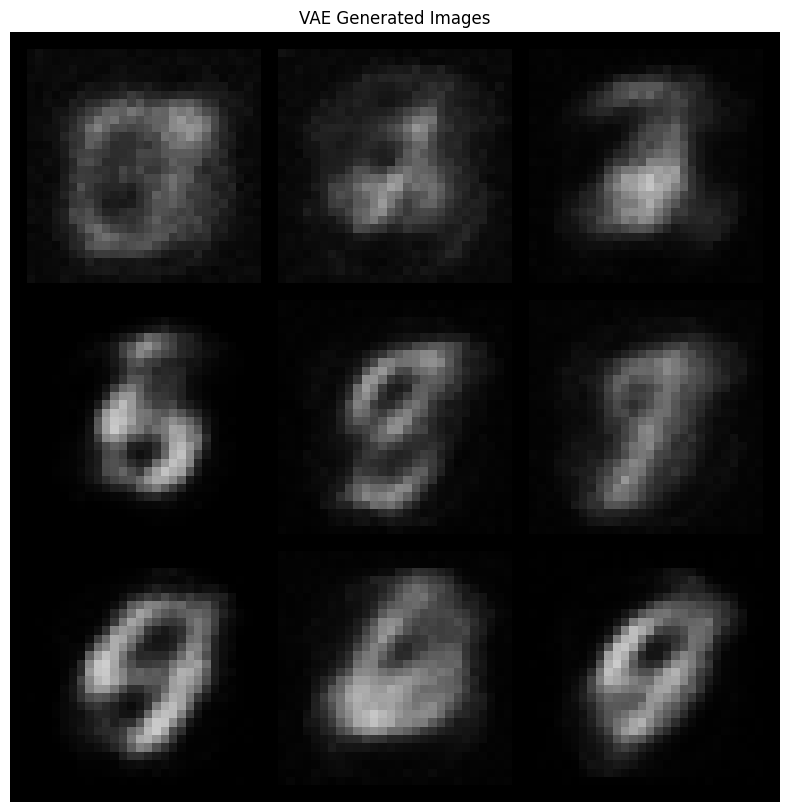

In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, Subset

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

image_size = 28
batch_size = 128
latent_dim = 20
epochs = 5
learning_rate = 0.001

transform = transforms.ToTensor()

dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


dataset = Subset(
    dataset,
    range(5000)
)

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Dataset loaded successfully!")
print("Training images:", len(dataset))




class Encoder(nn.Module):

    def __init__(self, latent_dim):

        super(Encoder, self).__init__()

        self.fc1 = nn.Linear(
            28 * 28,
            400
        )

        self.fc_mu = nn.Linear(
            400,
            latent_dim
        )

        self.fc_logvar = nn.Linear(
            400,
            latent_dim
        )

    def forward(self, x):

        x = x.view(
            x.size(0),
            -1
        )

        x = torch.relu(
            self.fc1(x)
        )

        mu = self.fc_mu(x)

        logvar = self.fc_logvar(x)

        return mu, logvar




class Decoder(nn.Module):

    def __init__(self, latent_dim):

        super(Decoder, self).__init__()

        self.fc1 = nn.Linear(
            latent_dim,
            400
        )

        self.fc2 = nn.Linear(
            400,
            28 * 28
        )

    def forward(self, z):

        x = torch.relu(
            self.fc1(z)
        )

        x = torch.sigmoid(
            self.fc2(x)
        )

        x = x.view(
            x.size(0),
            1,
            28,
            28
        )

        return x



class VAE(nn.Module):

    def __init__(self, latent_dim):

        super(VAE, self).__init__()

        self.encoder = Encoder(
            latent_dim
        )

        self.decoder = Decoder(
            latent_dim
        )

    def reparameterize(
        self,
        mu,
        logvar
    ):

        std = torch.exp(
            0.5 * logvar
        )

        epsilon = torch.randn_like(
            std
        )

        return (
            mu +
            epsilon * std
        )

    def forward(self, x):

        mu, logvar = self.encoder(x)

        z = self.reparameterize(
            mu,
            logvar
        )

        reconstructed = self.decoder(z)

        return reconstructed, mu, logvar



def vae_loss(
    reconstructed,
    original,
    mu,
    logvar
):

    reconstruction_loss = F.binary_cross_entropy(
        reconstructed,
        original,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1
        + logvar
        - mu.pow(2)
        - logvar.exp()
    )

    return reconstruction_loss + kl_loss

model = VAE(
    latent_dim
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)



print("\nTraining VAE...\n")

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, _ in dataloader:

        images = images.to(device)

        reconstructed, mu, logvar = model(
            images
        )

        loss = vae_loss(
            reconstructed,
            images,
            mu,
            logvar
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss /
        len(dataset)
    )

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {average_loss:.4f}"
    )

model.eval()

with torch.no_grad():

    z = torch.randn(
        9,
        latent_dim
    ).to(device)

    generated_images = model.decoder(
        z
    ).cpu()



grid = torchvision.utils.make_grid(
    generated_images,
    nrow=3
)

plt.figure(
    figsize=(10, 10)
)

plt.imshow(
    grid.permute(1, 2, 0)
)

plt.axis("off")

plt.title(
    "VAE Generated Images"
)

plt.show()